##Apolo BARNABAS


### 📱 Telecom Messaging Data Analysis and Customer Behavior Insights




### Part 1 — Install and import libraries

In [1]:
!pip -q install pandas numpy plotly scikit-learn

In [2]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from IPython.display import display
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
np.random.seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


#### Part 2 — Create a realistic synthetic dataset
This cell creates repeated customer IDs, which is important for customer behavior analysis and segmentation or to load the file in Part 3.

In [3]:
from datetime import datetime, timedelta

n_messages = 5000
n_customers = 500
start_date = pd.Timestamp("2025-01-01")
end_date = pd.Timestamp("2025-12-31")

customer_ids = [f"CUST_{i:04d}" for i in range(1, n_customers + 1)]
customer_regions = np.random.choice(
    ["North", "South", "East", "West", "Central"],
    size=n_customers,
    p=[0.20, 0.18, 0.17, 0.20, 0.25]
)
customer_fees = np.random.choice([19.99, 29.99, 39.99, 49.99, 59.99], size=n_customers)

customer_profile = pd.DataFrame({
    "customer_id": customer_ids,
    "region": customer_regions,
    "monthly_fee": customer_fees
})

message_customer_ids = np.random.choice(customer_ids, size=n_messages, replace=True)
profile_lookup = customer_profile.set_index("customer_id")

timestamps = start_date + pd.to_timedelta(
    np.random.randint(0, int((end_date - start_date).total_seconds()), size=n_messages),
    unit="s"
)
network_types = np.random.choice(["3G", "4G", "5G"], size=n_messages, p=[0.12, 0.53, 0.35])
message_types = np.random.choice(["SMS", "MMS", "App Message"], size=n_messages, p=[0.65, 0.15, 0.20])

# Slightly different latency by network type
latencies = []
statuses = []
for network in network_types:
    if network == "3G":
        latencies.append(max(10, np.random.normal(180, 55)))
        delivery_prob = 0.91
    elif network == "4G":
        latencies.append(max(5, np.random.normal(85, 25)))
        delivery_prob = 0.96
    else:
        latencies.append(max(2, np.random.normal(35, 12)))
        delivery_prob = 0.985
    statuses.append(np.random.choice(["Delivered", "Failed", "Pending"], p=[delivery_prob, (1-delivery_prob)*0.7, (1-delivery_prob)*0.3]))

df = pd.DataFrame({
    "message_id": [f"MSG_{i:06d}" for i in range(1, n_messages + 1)],
    "customer_id": message_customer_ids,
    "timestamp": timestamps,
    "message_type": message_types,
    "status": statuses,
    "network_type": network_types,
    "region": [profile_lookup.loc[c, "region"] for c in message_customer_ids],
    "latency_ms": np.round(latencies, 2),
    "monthly_fee": [profile_lookup.loc[c, "monthly_fee"] for c in message_customer_ids]
})

df = df.sort_values("timestamp").reset_index(drop=True)
print(f"Created {len(df):,} messages from {df['customer_id'].nunique():,} unique customers.")
display(df.head())

Created 5,000 messages from 500 unique customers.


,message_id,customer_id,timestamp,message_type,status,network_type,region,latency_ms,monthly_fee
0,MSG_002505,CUST_0252,2025-01-01 01:47:44,SMS,Delivered,5G,East,35.56,29.99
1,MSG_003583,CUST_0199,2025-01-01 05:19:16,SMS,Delivered,4G,Central,75.23,29.99
2,MSG_001817,CUST_0011,2025-01-01 06:00:50,SMS,Delivered,4G,North,67.66,59.99
3,MSG_004254,CUST_0284,2025-01-01 06:46:03,App Message,Delivered,5G,North,21.26,19.99
4,MSG_003812,CUST_0193,2025-01-01 07:21:45,SMS,Delivered,4G,Central,127.77,29.99


### Part 3 — Load my CSV (optional)
The upload lines below and upload a file with these columns: `message_id`, `customer_id`, `timestamp`, `message_type`, `status`, `network_type`, `region`, `latency_ms`, `monthly_fee`.

In [ ]:
# OPTIONAL: Upload my CSV in Google Colab.
# Uncomment the next two lines to use my file instead of the synthetic data.
# from google.colab import files
# uploaded = files.upload()  # Choose telecom_messaging_data.csv
# df = pd.read_csv("telecom_messaging_data.csv")

required_columns = [
    "message_id", "customer_id", "timestamp", "message_type", "status",
    "network_type", "region", "latency_ms", "monthly_fee"
]
missing = [col for col in required_columns if col not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

print("Dataset is ready:", df.shape)
display(df.head())

Dataset is ready: (5000, 9)


,message_id,customer_id,timestamp,message_type,status,network_type,region,latency_ms,monthly_fee
0,MSG_002505,CUST_0252,2025-01-01 01:47:44,SMS,Delivered,5G,East,35.56,29.99
1,MSG_003583,CUST_0199,2025-01-01 05:19:16,SMS,Delivered,4G,Central,75.23,29.99
2,MSG_001817,CUST_0011,2025-01-01 06:00:50,SMS,Delivered,4G,North,67.66,59.99
3,MSG_004254,CUST_0284,2025-01-01 06:46:03,App Message,Delivered,5G,North,21.26,19.99
4,MSG_003812,CUST_0193,2025-01-01 07:21:45,SMS,Delivered,4G,Central,127.77,29.99


## Part 4 — Understand and clean the data

In [4]:
print("Dataset shape:", df.shape)
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nMissing values before cleaning:")
display(df.isna().sum().to_frame("missing_values"))
print("\nDuplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df["latency_ms"] = pd.to_numeric(df["latency_ms"], errors="coerce")
df["monthly_fee"] = pd.to_numeric(df["monthly_fee"], errors="coerce")
df = df.dropna(subset=["message_id", "customer_id", "timestamp"]).copy()
df["month"] = df["timestamp"].dt.to_period("M").astype(str)

# Replace missing categorical values with an explicit label
for col in ["message_type", "status", "network_type", "region"]:
    df[col] = df[col].fillna("Unknown")

print("Shape after cleaning:", df.shape)
display(df.describe(include="all").T.head(15))

Dataset shape: (5000, 9)

Data types:


,dtype
message_id,object
customer_id,object
timestamp,datetime64[ns]
message_type,object
status,object
network_type,object
region,object
latency_ms,float64
monthly_fee,float64



Missing values before cleaning:


,missing_values
message_id,0
customer_id,0
timestamp,0
message_type,0
status,0
network_type,0
region,0
latency_ms,0
monthly_fee,0



Duplicate rows: 0
Shape after cleaning: (5000, 10)


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
message_id,5000,5000,MSG_000642,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,5000,500,CUST_0059,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,5000,NaN,NaN,NaN,2025-07-02 04:44:36.036199936,2025-01-01 01:47:44,2025-03-31 09:39:41.249999872,2025-07-02 02:20:58.500000,2025-10-03 00:07:47.500000,2025-12-30 23:56:05,NaN
message_type,5000,3,SMS,3244,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status,5000,3,Delivered,4810,NaN,NaN,NaN,NaN,NaN,NaN,NaN
network_type,5000,3,4G,2724,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,5000,5,Central,1276,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latency_ms,5000.0,NaN,NaN,NaN,79.873594,2.0,41.0175,72.0,102.2825,426.35,51.245207
monthly_fee,5000.0,NaN,NaN,NaN,39.672,19.99,29.99,39.99,49.99,59.99,14.377768
month,5000,12,2025-01,465,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Part 5 — KPI overview

In [5]:
total_messages = len(df)
total_customers = df["customer_id"].nunique()
delivery_rate = df["status"].astype(str).str.lower().eq("delivered").mean() * 100
avg_latency = df["latency_ms"].mean()
avg_monthly_fee = df.groupby("customer_id")["monthly_fee"].first().mean()

print(f"Total messages: {total_messages:,}")
print(f"Unique customers: {total_customers:,}")
print(f"Message delivery rate: {delivery_rate:.2f}%")
print(f"Average latency: {avg_latency:.2f} ms")
print(f"Average customer monthly fee: {avg_monthly_fee:.2f}")

Total messages: 5,000
Unique customers: 500
Message delivery rate: 96.20%
Average latency: 79.87 ms
Average customer monthly fee: 39.57


### Part 6 — Visualization 1: Message status distribution

In [6]:
status_counts = df["status"].value_counts().reset_index()
status_counts.columns = ["status", "messages"]
fig = px.pie(status_counts, names="status", values="messages", hole=0.45,
             title="1. Message Status Distribution")
fig.show()

## Visualization 2: Messages by network type

In [ ]:
network_counts = df.groupby("network_type").size().reset_index(name="messages")
fig = px.bar(network_counts, x="network_type", y="messages", color="network_type",
             title="2. Message Volume by Network Type",
             labels={"network_type": "Network Type", "messages": "Number of Messages"})
fig.show()

## Visualization 3: Messages by region

In [7]:
region_counts = df.groupby("region").size().reset_index(name="messages").sort_values("messages", ascending=False)
fig = px.bar(region_counts, x="region", y="messages", color="messages",
             title="3. Message Volume by Region",
             labels={"region": "Region", "messages": "Number of Messages"})
fig.show()

### Visualization 4: Monthly messaging trends

In [9]:
monthly_trend = df.groupby("month").size().reset_index(name="messages").sort_values("month")
fig = px.line(monthly_trend, x="month", y="messages", markers=True,
              title="4. Monthly Messaging Trends",
              labels={"month": "Month", "messages": "Number of Messages"})
fig.update_xaxes(tickangle=45)
fig.show()

### Visualization 5: Customer segmentation with K-Means

In [10]:
customer_data = df.groupby("customer_id").agg(
    total_messages=("message_id", "count"),
    avg_latency=("latency_ms", "mean"),
    monthly_fee=("monthly_fee", "first"),
    delivered_messages=("status", lambda s: s.astype(str).str.lower().eq("delivered").sum())
).reset_index()

customer_data["delivery_rate_pct"] = (
    customer_data["delivered_messages"] / customer_data["total_messages"] * 100
)

features = customer_data[["total_messages", "avg_latency", "monthly_fee"]].replace([np.inf, -np.inf], np.nan)
valid_idx = features.dropna().index
X = features.loc[valid_idx]

if len(X) >= 2:
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    k = min(3, len(X))
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    customer_data.loc[valid_idx, "segment"] = kmeans.fit_predict(X_scaled).astype(str)

    fig = px.scatter(
        customer_data.loc[valid_idx],
        x="total_messages", y="monthly_fee", color="segment",
        hover_data=["customer_id", "avg_latency", "delivery_rate_pct"],
        title="5. Customer Segments: Message Usage vs Monthly Fee",
        labels={"total_messages": "Total Messages", "monthly_fee": "Monthly Fee", "segment": "K-Means Segment"}
    )
    fig.show()
    print("Customer segment profile:")
    display(customer_data.groupby("segment")[["total_messages", "avg_latency", "monthly_fee", "delivery_rate_pct"]].mean().round(2))
else:
    print("Not enough complete customer records for K-Means.")

Customer segment profile:


,total_messages,avg_latency,monthly_fee,delivery_rate_pct
segment,,,,
0,10.58,75.17,55.70,96.40
1,10.44,72.63,29.18,96.28
2,7.90,106.23,36.34,95.69


### Visualization 6: Network performance

In [11]:
network_performance = df.groupby("network_type").agg(
    average_latency_ms=("latency_ms", "mean"),
    messages=("message_id", "count"),
    delivery_rate_pct=("status", lambda s: s.astype(str).str.lower().eq("delivered").mean() * 100)
).reset_index()

fig = px.bar(network_performance, x="network_type", y="average_latency_ms",
             color="network_type", title="6A. Average Latency by Network",
             labels={"network_type": "Network Type", "average_latency_ms": "Average Latency (ms)"})
fig.show()

fig = px.bar(network_performance, x="network_type", y="delivery_rate_pct",
             color="network_type", title="6B. Delivery Rate by Network",
             labels={"network_type": "Network Type", "delivery_rate_pct": "Delivery Rate (%)"})
fig.show()

display(network_performance.round(2))

,network_type,average_latency_ms,messages,delivery_rate_pct
0,3G,179.56,595,92.10
1,4G,85.55,2724,95.70
2,5G,35.40,1681,98.45


## Visualization 7: Top 10 customers by message volume

In [12]:
top_customers = customer_data.nlargest(10, "total_messages").copy()
top_customers["customer_label"] = top_customers["customer_id"].astype(str)
fig = px.bar(top_customers.sort_values("total_messages"), x="total_messages", y="customer_label",
             orientation="h", title="7. Top 10 Customers by Message Volume",
             labels={"total_messages": "Messages", "customer_label": "Customer ID"})
fig.show()

## Visualization 8: Customer behavior metrics

In [13]:
customer_metrics = customer_data.sort_values("total_messages", ascending=False)
display(customer_metrics.head(20).round(2))

fig = px.histogram(customer_data, x="total_messages", nbins=30,
                   title="8. Distribution of Messages per Customer",
                   labels={"total_messages": "Messages per Customer"})
fig.show()

,customer_id,total_messages,avg_latency,monthly_fee,delivered_messages,delivery_rate_pct,segment
58,CUST_0059,22,76.02,49.99,21,95.45,0
153,CUST_0154,19,83.39,49.99,18,94.74,0
83,CUST_0084,18,70.46,29.99,18,100.00,1
424,CUST_0425,18,78.35,29.99,17,94.44,1
11,CUST_0012,18,78.73,29.99,18,100.00,1
187,CUST_0188,18,81.24,49.99,16,88.89,0
312,CUST_0313,18,74.36,29.99,18,100.00,1
449,CUST_0450,18,74.75,29.99,18,100.00,1
309,CUST_0310,17,84.34,39.99,17,100.00,1
404,CUST_0405,17,101.35,29.99,16,94.12,1


## Visualization 9: Monthly performance report

In [14]:
monthly_report = df.groupby("month").agg(
    total_messages=("message_id", "count"),
    unique_customers=("customer_id", "nunique"),
    average_latency_ms=("latency_ms", "mean"),
    delivered_messages=("status", lambda s: s.astype(str).str.lower().eq("delivered").sum())
).reset_index().sort_values("month")

monthly_report["delivery_rate_pct"] = (
    monthly_report["delivered_messages"] / monthly_report["total_messages"] * 100
)
display(monthly_report.round(2))

fig = px.bar(monthly_report, x="month", y="total_messages",
             title="9. Monthly Performance Report — Message Volume",
             labels={"month": "Month", "total_messages": "Messages"})
fig.update_xaxes(tickangle=45)
fig.show()

,month,total_messages,unique_customers,average_latency_ms,delivered_messages,delivery_rate_pct
0,2025-01,465,306,76.67,447,96.13
1,2025-02,373,258,78.58,357,95.71
2,2025-03,430,275,83.53,416,96.74
3,2025-04,401,273,80.16,383,95.51
4,2025-05,414,287,81.68,395,95.41
5,2025-06,408,272,77.92,391,95.83
6,2025-07,380,266,78.23,371,97.63
7,2025-08,443,300,80.32,428,96.61
8,2025-09,407,283,79.71,395,97.05
9,2025-10,412,273,80.66,398,96.60


## Visualization 10: Business insights and recommendations

In [15]:
print("10. BUSINESS INSIGHTS & RECOMMENDATIONS")
print("=" * 55)

if not network_performance.empty:
    best_delivery = network_performance.loc[network_performance["delivery_rate_pct"].idxmax()]
    worst_latency = network_performance.loc[network_performance["average_latency_ms"].idxmax()]
    print(f"• Highest observed delivery rate: {best_delivery['network_type']} "
          f"({best_delivery['delivery_rate_pct']:.1f}%).")
    print(f"• Highest average latency: {worst_latency['network_type']} "
          f"({worst_latency['average_latency_ms']:.1f} ms). Investigate possible network bottlenecks.")

if not region_counts.empty:
    busiest_region = region_counts.iloc[0]
    print(f"• Highest message volume region: {busiest_region['region']} "
          f"({int(busiest_region['messages']):,} messages).")

print(f"• Dataset includes {df['customer_id'].nunique():,} unique customers and {len(df):,} messages.")
print("• Recommendation: monitor delivery failures and latency by region and network.")
print("• Recommendation: tailor customer retention campaigns using usage patterns and segments.")
print("• Recommendation: validate these findings against real operational data before business decisions.")

10. BUSINESS INSIGHTS & RECOMMENDATIONS
• Highest observed delivery rate: 5G (98.5%).
• Highest average latency: 3G (179.6 ms). Investigate possible network bottlenecks.
• Highest message volume region: Central (1,276 messages).
• Dataset includes 500 unique customers and 5,000 messages.
• Recommendation: monitor delivery failures and latency by region and network.
• Recommendation: tailor customer retention campaigns using usage patterns and segments.
• Recommendation: validate these findings against real operational data before business decisions.


## Export the dataset and reports

In [19]:
df.to_csv("telecom_messaging_data.csv", index=False)
customer_data.to_csv("telecom_customer_analysis.csv", index=False)
monthly_report.to_csv("telecom_monthly_report.csv", index=False)

print("Saved files:")
print("- telecom_messaging_data.csv")
print("- telecom_customer_analysis.csv")
print("- telecom_monthly_report.csv")

Saved files:
- telecom_messaging_data.csv
- telecom_customer_analysis.csv
- telecom_monthly_report.csv


In [17]:
!pip install -q pandas numpy plotly streamlit scikit-learn faker

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 70.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 78.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 94.9 MB/s eta 0:00:00


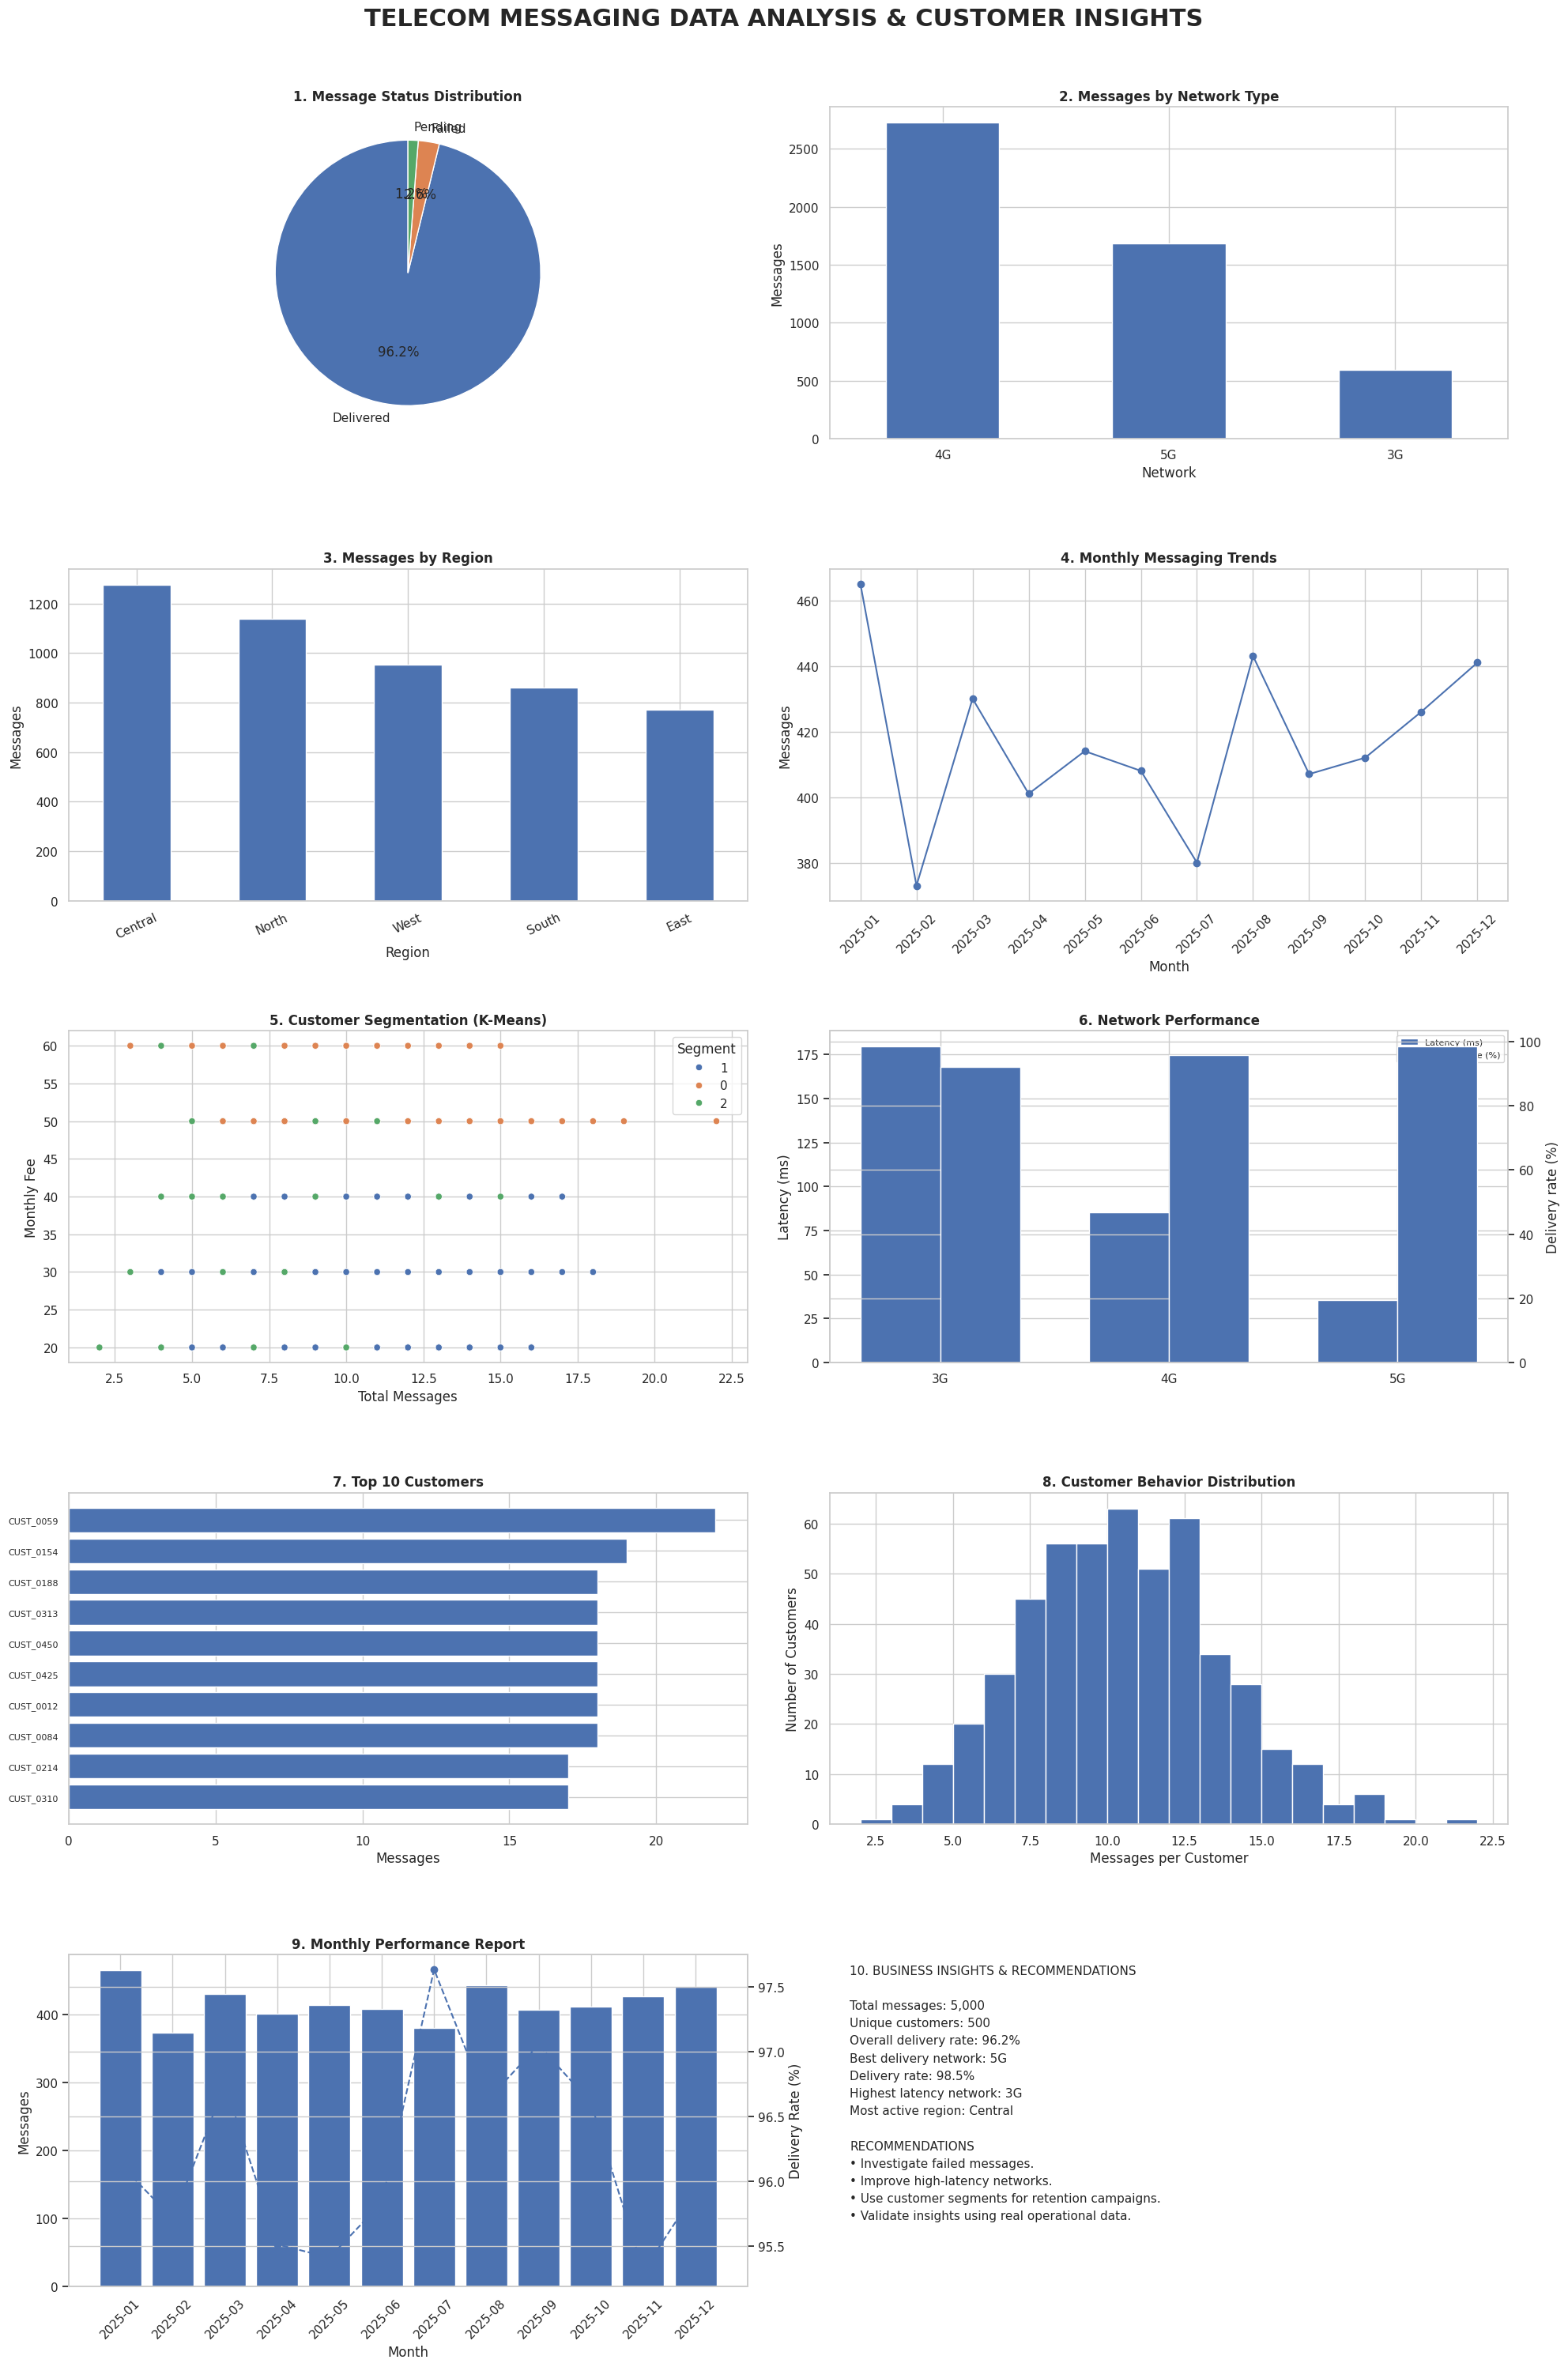

Dashboard saved as: telecom_10_visualizations_dashboard.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
# TELECOM PROJECT: ALL 10 VISUALIZATIONS ON ONE PAGE
# Output: telecom_10_visualizations_dashboard.png

!pip -q install matplotlib seaborn scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# If df is not already loaded, uncomment:
# df = pd.read_csv("telecom_messaging_data.csv")

# 1. Prepare data
df = df.copy()
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df["latency_ms"] = pd.to_numeric(df["latency_ms"], errors="coerce")
df["monthly_fee"] = pd.to_numeric(df["monthly_fee"], errors="coerce")
df = df.dropna(subset=["customer_id", "timestamp", "message_id"])

for col in ["status", "network_type", "region", "message_type"]:
    df[col] = df[col].fillna("Unknown")

df["month"] = df["timestamp"].dt.to_period("M").astype(str)

# 2. Calculate summaries
status = df["status"].value_counts()
network = df["network_type"].value_counts()
region = df["region"].value_counts().sort_values(ascending=False)
monthly = df.groupby("month").size().sort_index()

customers = df.groupby("customer_id").agg(
    total_messages=("message_id", "count"),
    avg_latency=("latency_ms", "mean"),
    monthly_fee=("monthly_fee", "first"),
    delivered=("status", lambda x:
        x.astype(str).str.lower().eq("delivered").sum())
).reset_index()

customers["delivery_rate"] = (
    customers["delivered"] /
    customers["total_messages"] * 100
)

network_perf = df.groupby("network_type").agg(
    latency=("latency_ms", "mean"),
    delivery_rate=("status", lambda x:
        x.astype(str).str.lower().eq("delivered").mean() * 100)
).reset_index()

# 3. K-Means customer segmentation
features = customers[
    ["total_messages", "avg_latency", "monthly_fee"]
].replace([np.inf, -np.inf], np.nan)

valid = features.dropna().index

if len(valid) >= 2:
    scaler = StandardScaler()
    X = scaler.fit_transform(features.loc[valid])
    k = min(3, len(valid))

    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    customers["segment"] = np.nan
    customers.loc[valid, "segment"] = model.fit_predict(X).astype(str)
else:
    customers["segment"] = "Unavailable"

# 4. Create one page with 10 charts (2 columns x 5 rows)
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(5, 2, figsize=(20, 30))
ax = ax.flatten()

fig.suptitle(
    "TELECOM MESSAGING DATA ANALYSIS & CUSTOMER INSIGHTS",
    fontsize=22, fontweight="bold", y=0.998
)

# Visualization 1: Message status
ax[0].pie(
    status.values,
    labels=status.index,
    autopct="%1.1f%%",
    startangle=90
)
ax[0].set_title("1. Message Status Distribution", fontweight="bold")

# Visualization 2: Network type
network.plot(kind="bar", ax=ax[1])
ax[1].set_title("2. Messages by Network Type", fontweight="bold")
ax[1].set_xlabel("Network")
ax[1].set_ylabel("Messages")
ax[1].tick_params(axis="x", rotation=0)

# Visualization 3: Region
region.plot(kind="bar", ax=ax[2])
ax[2].set_title("3. Messages by Region", fontweight="bold")
ax[2].set_xlabel("Region")
ax[2].set_ylabel("Messages")
ax[2].tick_params(axis="x", rotation=25)

# Visualization 4: Monthly trends
ax[3].plot(monthly.index, monthly.values, marker="o")
ax[3].set_title("4. Monthly Messaging Trends", fontweight="bold")
ax[3].set_xlabel("Month")
ax[3].set_ylabel("Messages")
ax[3].tick_params(axis="x", rotation=45)

# Visualization 5: Customer segmentation
if customers["segment"].nunique() > 1:
    sns.scatterplot(
        data=customers,
        x="total_messages",
        y="monthly_fee",
        hue="segment",
        ax=ax[4]
    )
    ax[4].legend(title="Segment")
else:
    ax[4].text(0.5, 0.5, "Not enough data for segmentation",
               ha="center", va="center")

ax[4].set_title("5. Customer Segmentation (K-Means)", fontweight="bold")
ax[4].set_xlabel("Total Messages")
ax[4].set_ylabel("Monthly Fee")

# Visualization 6: Network performance
x = np.arange(len(network_perf))
width = 0.35

ax[5].bar(
    x - width / 2,
    network_perf["latency"],
    width,
    label="Latency (ms)"
)
ax[5].set_ylabel("Latency (ms)")
ax[5].set_xticks(x)
ax[5].set_xticklabels(network_perf["network_type"])
ax[5].set_title("6. Network Performance", fontweight="bold")

ax6b = ax[5].twinx()
ax6b.bar(
    x + width / 2,
    network_perf["delivery_rate"],
    width,
    label="Delivery rate (%)"
)
ax6b.set_ylabel("Delivery rate (%)")

h1, l1 = ax[5].get_legend_handles_labels()
h2, l2 = ax6b.get_legend_handles_labels()
ax[5].legend(h1 + h2, l1 + l2, fontsize=8)

# Visualization 7: Top 10 customers
top10 = customers.nlargest(10, "total_messages").sort_values(
    "total_messages"
)
ax[6].barh(
    top10["customer_id"].astype(str),
    top10["total_messages"]
)
ax[6].set_title("7. Top 10 Customers", fontweight="bold")
ax[6].set_xlabel("Messages")
ax[6].tick_params(axis="y", labelsize=8)

# Visualization 8: Customer message distribution
ax[7].hist(customers["total_messages"], bins=20)
ax[7].set_title("8. Customer Behavior Distribution", fontweight="bold")
ax[7].set_xlabel("Messages per Customer")
ax[7].set_ylabel("Number of Customers")

# Visualization 9: Monthly performance
monthly_report = df.groupby("month").agg(
    messages=("message_id", "count"),
    delivery_rate=("status", lambda x:
        x.astype(str).str.lower().eq("delivered").mean() * 100)
).reset_index().sort_values("month")

ax[8].bar(monthly_report["month"], monthly_report["messages"])
ax[8].set_title("9. Monthly Performance Report", fontweight="bold")
ax[8].set_xlabel("Month")
ax[8].set_ylabel("Messages")
ax[8].tick_params(axis="x", rotation=45)

ax9b = ax[8].twinx()
ax9b.plot(
    monthly_report["month"],
    monthly_report["delivery_rate"],
    marker="o",
    linestyle="--"
)
ax9b.set_ylabel("Delivery Rate (%)")

# Visualization 10: Business insights
ax[9].axis("off")

best_network = network_perf.loc[
    network_perf["delivery_rate"].idxmax()
]
slowest_network = network_perf.dropna(
    subset=["latency"]
).sort_values("latency", ascending=False)

overall_delivery = (
    df["status"].astype(str).str.lower().eq("delivered").mean() * 100
)

insights = [
    "10. BUSINESS INSIGHTS & RECOMMENDATIONS",
    "",
    f"Total messages: {len(df):,}",
    f"Unique customers: {df['customer_id'].nunique():,}",
    f"Overall delivery rate: {overall_delivery:.1f}%",
    f"Best delivery network: {best_network['network_type']}",
    f"Delivery rate: {best_network['delivery_rate']:.1f}%",
    (
        f"Highest latency network: {slowest_network.iloc[0]['network_type']}"
        if not slowest_network.empty else "Latency data unavailable"
    ),
    f"Most active region: {region.index[0]}",
    "",
    "RECOMMENDATIONS",
    "• Investigate failed messages.",
    "• Improve high-latency networks.",
    "• Use customer segments for retention campaigns.",
    "• Validate insights using real operational data."
]

ax[9].text(
    0.03, 0.97, "\n".join(insights),
    va="top", ha="left", fontsize=11, linespacing=1.6
)

# 5. Save the complete dashboard as one image
plt.tight_layout(rect=[0, 0, 1, 0.985], h_pad=3, w_pad=2)

filename = "telecom_10_visualizations_dashboard.png"
fig.savefig(filename, dpi=220, bbox_inches="tight")
plt.show()

print(f"Dashboard saved as: {filename}")

# 6. Download image automatically in Google Colab
from google.colab import files
files.download(filename)

## Project conclusion
This demonstrates a complete analytics workflow:
1. Dataset creation/loading
2. Data understanding and cleaning
3. KPI calculation
4. Messaging and regional trend analysis
5. Customer segmentation with K-Means
6. Network performance analysis
7. Customer-level reporting
8. Business insights and recommendations
